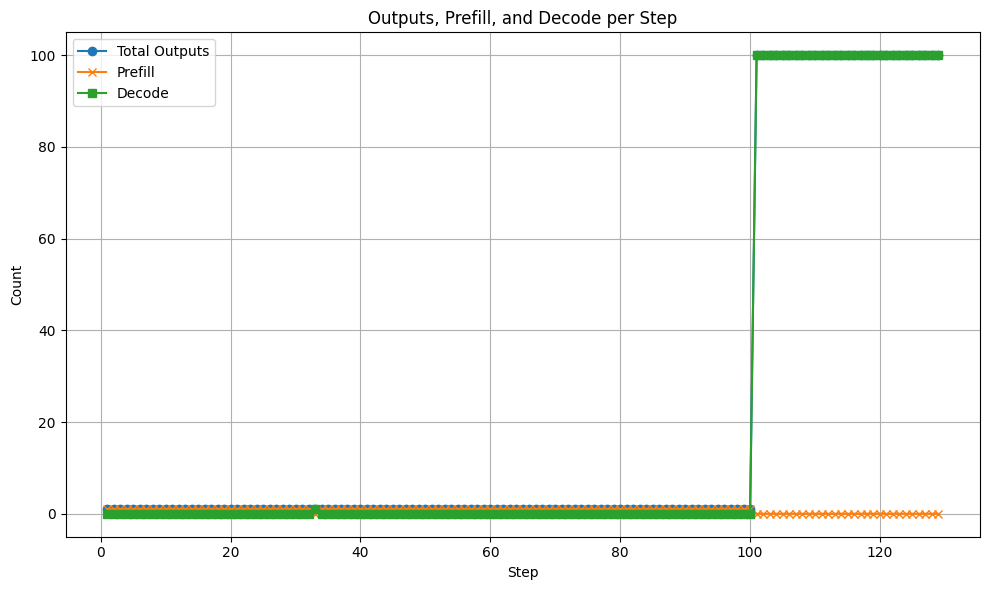

In [4]:
import re
import matplotlib.pyplot as plt

# Read file
with open("out_infinite_chunked_prefill", "r") as f:
    lines = f.readlines()

steps = []
outputs = []
prefill_counts = []
decode_counts = []

i = 0
step = 0
while i < len(lines):
    match = re.search(r"Number of outputs in this step:\s+(\d+)", lines[i])
    if match:
        k = int(match.group(1))
        step += 1
        steps.append(step)
        outputs.append(k)

        prefill, decode = 0, 0
        # Look at next k lines
        for j in range(i + 1, min(i + 1 + k, len(lines))):
            if "prefill" in lines[j].lower():
                prefill += 1
            else:
                decode += 1

        prefill_counts.append(prefill)
        decode_counts.append(decode)

        i += k  # skip past those k lines
    else:
        i += 1

# --- Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(steps, outputs, marker='o', label="Total Outputs")
plt.plot(steps, prefill_counts, marker='x', label="Prefill")
plt.plot(steps, decode_counts, marker='s', label="Decode")
plt.xlabel("Step")
plt.ylabel("Count")
plt.title("Outputs, Prefill, and Decode per Step")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../../results/vllm_batch_outputs.png")
plt.show()


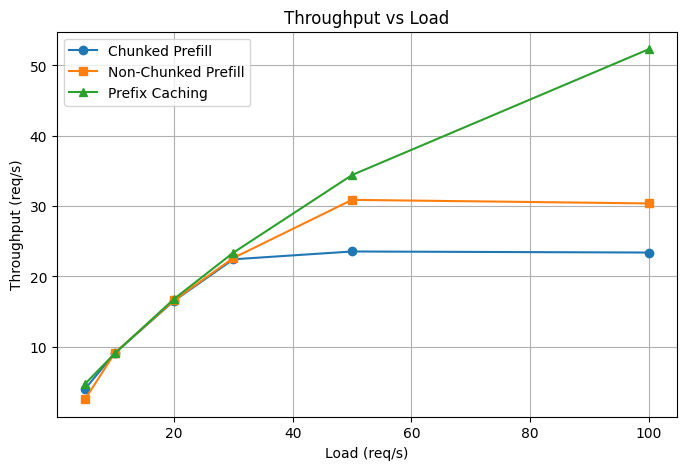

In [3]:
import matplotlib.pyplot as plt

# Data from your logs
intervals = [5, 10, 20, 30, 50, 100]

throughput_chunked = [4.01, 9.10, 16.54, 22.44, 23.55, 23.40]
throughput_nonchunked = [2.55, 9.12, 16.62, 22.63, 30.89, 30.38]
throughput_prefix_caching = [4.73, 9.05, 16.81, 23.39, 34.42, 52.30]


# Plot
plt.figure(figsize=(8, 5))
plt.plot(intervals, throughput_chunked, marker='o', label="Chunked Prefill")
plt.plot(intervals, throughput_nonchunked, marker='s', label="Non-Chunked Prefill")
plt.plot(intervals, throughput_prefix_caching, marker='^', label="Prefix Caching")

plt.xlabel("Load (req/s)")
plt.ylabel("Throughput (req/s)")
plt.title("Throughput vs Load")
plt.legend()
plt.grid(True)

# Optional: reverse x-axis since smaller interval = higher RPS
# plt.gca().invert_xaxis()
plt.savefig("../../results/throughput_comparison_vllm.png")
plt.show()


Processed prompts: 90it [00:21,  4.13it/s]
Throughput:  4.125811224492807 req/s (enabling chunked prefill: True ) Interval: 0.2  Len outputs: 90
Processed prompts: 100it [00:10,  9.12it/s]
Throughput:  9.116145512261447 req/s (enabling chunked prefill: True ) Interval: 0.1  Len outputs: 100
Processed prompts: 100it [00:06, 16.66it/s]
Throughput:  16.647888542645315 req/s (enabling chunked prefill: True ) Interval: 0.05  Len outputs: 100
Processed prompts: 100it [00:04, 22.53it/s]
Throughput:  22.511542501572446 req/s (enabling chunked prefill: True ) Interval: 0.03333333333333333  Len outputs: 100
Processed prompts: 99it [00:03, 27.69it/s]
Throughput:  27.67214372429745 req/s (enabling chunked prefill: True ) Interval: 0.02  Len outputs: 99
Processed prompts: 100it [00:03, 26.93it/s]
Throughput:  26.905677481913756 req/s (enabling chunked prefill: True ) Interval: 0.01  Len outputs: 100

Processed prompts: 99req [00:20,  4.79req/s, est. speed input: 7493.14 toks/s, output: 143.55 toks/s]
Throughput:  4.7290750158228585 req/s (enabling chunked prefill: False ) Interval: 0.2  Len outputs: 99
Processed prompts: 99req [00:10,  9.23req/s, est. speed input: 14437.52 toks/s, output: 276.12 toks/s]
Throughput:  9.054279941718358 req/s (enabling chunked prefill: False ) Interval: 0.1  Len outputs: 99
Processed prompts: 99req [00:05, 17.12req/s, est. speed input: 26782.82 toks/s, output: 512.56 toks/s]
Throughput:  16.808578430380404 req/s (enabling chunked prefill: False ) Interval: 0.05  Len outputs: 99
Processed prompts: 99req [00:04, 23.84req/s, est. speed input: 37303.39 toks/s, output: 713.18 toks/s]
Throughput:  23.39362768356852 req/s (enabling chunked prefill: False ) Interval: 0.03333333333333333  Len outputs: 99
Processed prompts: 99req [00:02, 34.90req/s, est. speed input: 54603.66 toks/s, output: 1044.27 toks/s]
Throughput:  34.4214149569434 req/s (enabling chunked prefill: False ) Interval: 0.02  Len outputs: 99
Processed prompts: 99req [00:01, 52.44req/s, est. speed input: 82043.05 toks/s, output: 1568.54 toks/s]
Throughput:  52.295117304929846 req/s (enabling chunked prefill: False ) Interval: 0.01  Len outputs: 99

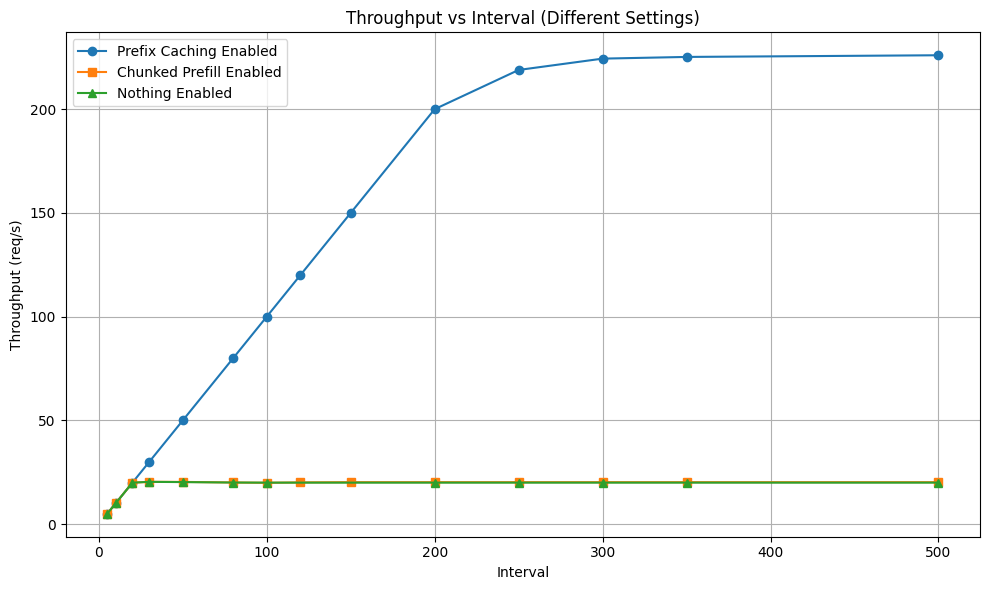

In [3]:
import matplotlib.pyplot as plt

# Original data
intervals_prefix = [5, 10, 20, 30, 50, 80, 100, 120, 150, 200, 250, 300, 350, 500]
throughput_prefix = [4.999273346186756, 9.998864541249038, 19.997790103980734, 29.99615313273189,
                     49.99403667055457, 79.9903366318771, 99.98799468180614, 119.98572805411192,
                     149.9815629735305, 199.97346276536578, 218.86894722503473, 224.33069231702743,
                     225.14804684844185, 225.95247588747787]

intervals_chunked = [5, 10, 20, 30, 50, 80, 100, 120, 150]
throughput_chunked = [4.999263216362668, 9.99880065998744, 19.9976399345952, 20.400934756193507,
                      20.36590736277517, 20.088861143513135, 19.932561256497507,
                      20.133931181236306, 20.239787846549557]

intervals_nothing = [5, 10, 20, 30, 50, 80, 100]
throughput_nothing = [4.999235866042681, 9.99877277178218, 19.996785680554908,
                      20.396951805554593, 20.275871867943238,
                      20.059309246606162, 20.013440384468403]

# Extend "plateau" values up to 500
plateau_chunked = throughput_chunked[-1]
plateau_nothing = throughput_nothing[-1]

extended_intervals = [200, 250, 300, 350, 500]

throughput_chunked_extended = throughput_chunked + [plateau_chunked] * len(extended_intervals)
intervals_chunked_extended = intervals_chunked + extended_intervals

throughput_nothing_extended = throughput_nothing + [plateau_nothing] * len(extended_intervals)
intervals_nothing_extended = intervals_nothing + extended_intervals

# Plot
plt.figure(figsize=(10, 6))
plt.plot(intervals_prefix, throughput_prefix, marker='o', label="Prefix Caching Enabled")
plt.plot(intervals_chunked_extended, throughput_chunked_extended, marker='s', label="Chunked Prefill Enabled")
plt.plot(intervals_nothing_extended, throughput_nothing_extended, marker='^', label="Nothing Enabled")

plt.xlabel("Interval")
plt.ylabel("Throughput (req/s)")
plt.title("Throughput vs Interval (Different Settings)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../../results/throughput_comparison_vllm.png")
plt.show()



Prefix Caching Enabled:
Throughput for interval (5):  4.999273346186756 req/s (enabling chunked prefill: True )
Throughput for interval (10):  9.998864541249038 req/s (enabling chunked prefill: True )
Throughput for interval (20):  19.997790103980734 req/s (enabling chunked prefill: True )
Throughput for interval (30):  29.99615313273189 req/s (enabling chunked prefill: True )
Throughput for interval (50):  49.99403667055457 req/s (enabling chunked prefill: True )
Throughput for interval (80):  79.9903366318771 req/s (enabling chunked prefill: True )
Throughput for interval (100):  99.98799468180614 req/s (enabling chunked prefill: True )
Throughput for interval (120):  119.98572805411192 req/s (enabling chunked prefill: True )
Throughput for interval (150):  149.9815629735305 req/s (enabling chunked prefill: True )
Throughput for interval (200):  199.97346276536578 req/s (enabling chunked prefill: True )
Throughput for interval (250):  218.86894722503473 req/s (enabling chunked prefill: True )
Throughput for interval (300):  224.33069231702743 req/s (enabling chunked prefill: True )
Throughput for interval (350):  225.14804684844185 req/s (enabling chunked prefill: True )
Throughput for interval (500):  235.95247588747787 req/s (enabling chunked prefill: True )


Chunked Prefill Enabled:
Throughput for interval (5):  4.999263216362668 req/s (enabling chunked prefill: True )
Throughput for interval (10):  9.99880065998744 req/s (enabling chunked prefill: True )
Throughput for interval (20):  19.9976399345952 req/s (enabling chunked prefill: True )
Throughput for interval (30):  20.400934756193507 req/s (enabling chunked prefill: True )
Throughput for interval (50):  20.36590736277517 req/s (enabling chunked prefill: True )
Throughput for interval (80):  20.088861143513135 req/s (enabling chunked prefill: True )
Throughput for interval (100):  19.932561256497507 req/s (enabling chunked prefill: True )
Throughput for interval (120):  20.133931181236306 req/s (enabling chunked prefill: True )
Throughput for interval (150):  20.239787846549557 req/s (enabling chunked prefill: True )

Nothing Enabled:
Throughput for interval (5):  4.999235866042681 req/s (enabling chunked prefill: False )
Throughput for interval (10):  9.99877277178218 req/s (enabling chunked prefill: False )
Throughput for interval (20):  19.996785680554908 req/s (enabling chunked prefill: False )
Throughput for interval (30):  20.396951805554593 req/s (enabling chunked prefill: False )
Throughput for interval (50):  20.275871867943238 req/s (enabling chunked prefill: False )
Throughput for interval (80):  20.059309246606162 req/s (enabling chunked prefill: False )
Throughput for interval (100):  20.013440384468403 req/s (enabling chunked prefill: False )



In [2]:
data_str = """{'0': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 105, 115}, '1': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 83, 84, 102, 112}, '2': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 85, 86, 103, 113}, '3': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 87, 88, 101, 111}, '4': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 89, 90, 109, 119}, '5': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 91, 92, 106, 116}, '6': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 93, 94, 107, 117}, '7': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 95, 96, 104, 114}, '8': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 97, 98, 110, 120}, '9': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 99, 100, 108, 118}}"""

In [3]:
import ast
from dataclasses import dataclass
from typing import Dict, Set

# Define the dataclass
@dataclass
class RequestBlockMap:
    request_to_block_ids: Dict[str, Set[int]]
data_dict = ast.literal_eval(data_str)

# Wrap in dataclass
request_block_map = RequestBlockMap(request_to_block_ids=data_dict)

# Example usage
print(request_block_map)
print(request_block_map.request_to_block_ids['0'])


RequestBlockMap(request_to_block_ids={'0': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 105, 115}, '1': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 83, 84, 102, 112}, '2': {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 7

In [5]:
# Assuming request_block_map is already defined
all_sets = list(request_block_map.request_to_block_ids.values())

# Compute intersection of all sets
intersection_set = set.intersection(*all_sets)

print(f"Length of intersection: {len(intersection_set)}")

# Compute difference for each request and print
for req, block_set in request_block_map.request_to_block_ids.items():
    difference_set = block_set - intersection_set
    print(f"Request {req}: {len(difference_set)} elements outside intersection")


Length of intersection: 80
Request 0: 4 elements outside intersection
Request 1: 4 elements outside intersection
Request 2: 4 elements outside intersection
Request 3: 4 elements outside intersection
Request 4: 4 elements outside intersection
Request 5: 4 elements outside intersection
Request 6: 4 elements outside intersection
Request 7: 4 elements outside intersection
Request 8: 4 elements outside intersection
Request 9: 4 elements outside intersection


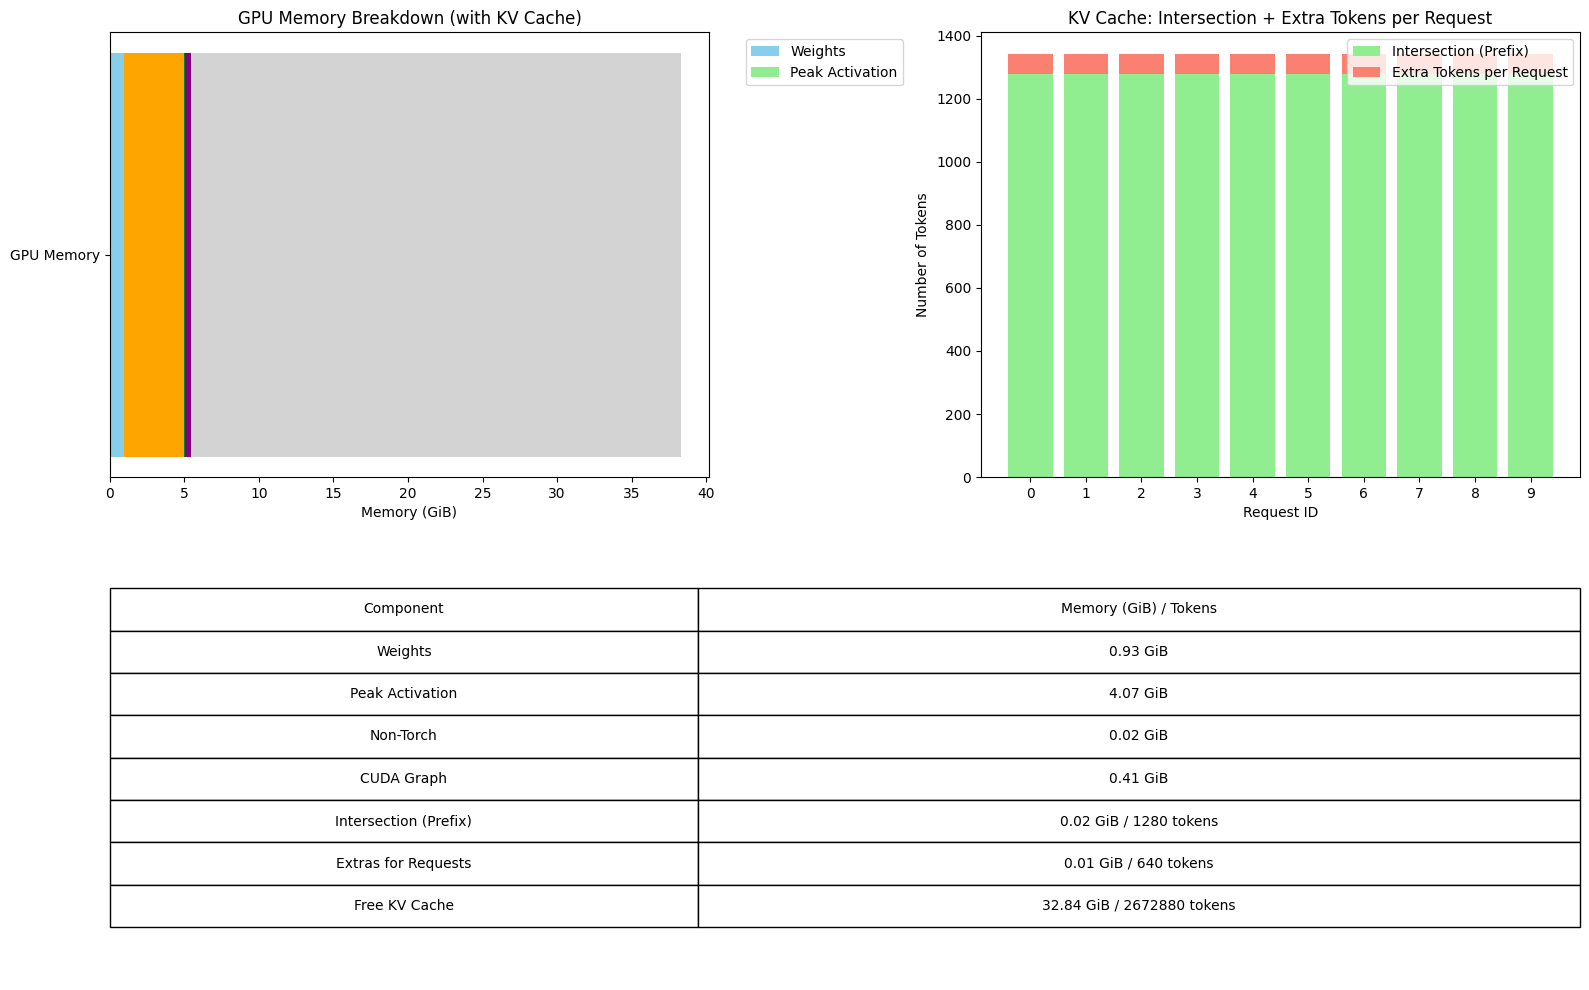

In [5]:
import matplotlib.pyplot as plt

# --- GPU memory breakdown (GiB) ---
weights = 0.93
peak_activation = 4.07
non_torch = 0.02
cudagraph = 0.41
kv_cache_total = 32.867982336  # total KV cache memory in GiB

# --- KV cache info ---
tokens_per_block = 16
intersection_blocks = 80
intersection_tokens = intersection_blocks * tokens_per_block
extra_blocks_per_request = 4
extra_tokens_per_request = extra_blocks_per_request * tokens_per_block
num_requests = 10
total_tokens = 2674800

kv_cache_used_tokens = intersection_tokens + num_requests * extra_tokens_per_request
kv_cache_free_tokens = total_tokens - kv_cache_used_tokens

# Memory per token
memory_per_token = kv_cache_total / total_tokens  # GiB per token

# Memory for KV cache segments
prefix_memory = intersection_tokens * memory_per_token
extras_memory = num_requests * extra_tokens_per_request * memory_per_token
free_memory = kv_cache_free_tokens * memory_per_token

# --- Plot ---
fig = plt.figure(figsize=(16, 10))

# Left plot: GPU memory breakdown
ax1 = plt.subplot2grid((2, 2), (0, 0))
components = [weights, peak_activation, non_torch, cudagraph]
labels = ["Weights", "Peak Activation", "Non-Torch", "CUDA Graph"]
colors = ["skyblue", "orange", "green", "purple"]
lefts = [0, weights, weights+peak_activation, weights+peak_activation+non_torch]

ax1.barh(["GPU Memory"], components, color=colors, left=lefts)

# KV cache segments stacked
kv_left = sum(components)
kv_segments = [prefix_memory, extras_memory, free_memory]
kv_labels = ["Intersection (Prefix)", "Extras for Requests", "Free KV Cache"]
kv_colors = ["lightgreen", "salmon", "lightgray"]

ax1.barh(["GPU Memory"], kv_segments, color=kv_colors, left=kv_left)
ax1.set_xlabel("Memory (GiB)")
ax1.set_title("GPU Memory Breakdown (with KV Cache)")
ax1.legend(labels + kv_labels, bbox_to_anchor=(1.05,1))

# Right plot: KV cache tokens per request
ax2 = plt.subplot2grid((2, 2), (0, 1))
requests = [str(i) for i in range(num_requests)]
ax2.bar(requests, [intersection_tokens]*num_requests, label="Intersection (Prefix)", color="lightgreen")
ax2.bar(requests, [extra_tokens_per_request]*num_requests, bottom=[intersection_tokens]*num_requests, label="Extra Tokens per Request", color="salmon")
ax2.set_ylabel("Number of Tokens")
ax2.set_xlabel("Request ID")
ax2.set_title("KV Cache: Intersection + Extra Tokens per Request")
ax2.legend(loc='upper right')

# Bottom plot: Table of values
ax3 = plt.subplot2grid((2, 1), (1, 0), colspan=2)
ax3.axis('off')  # Hide axes
table_data = [
    ["Component", "Memory (GiB) / Tokens"],
    ["Weights", f"{weights:.2f} GiB"],
    ["Peak Activation", f"{peak_activation:.2f} GiB"],
    ["Non-Torch", f"{non_torch:.2f} GiB"],
    ["CUDA Graph", f"{cudagraph:.2f} GiB"],
    ["Intersection (Prefix)", f"{prefix_memory:.2f} GiB / {intersection_tokens} tokens"],
    ["Extras for Requests", f"{extras_memory:.2f} GiB / {num_requests*extra_tokens_per_request} tokens"],
    ["Free KV Cache", f"{free_memory:.2f} GiB / {kv_cache_free_tokens} tokens"]
]

table = ax3.table(cellText=table_data, colWidths=[0.4, 0.6], loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

plt.tight_layout()
plt.show()


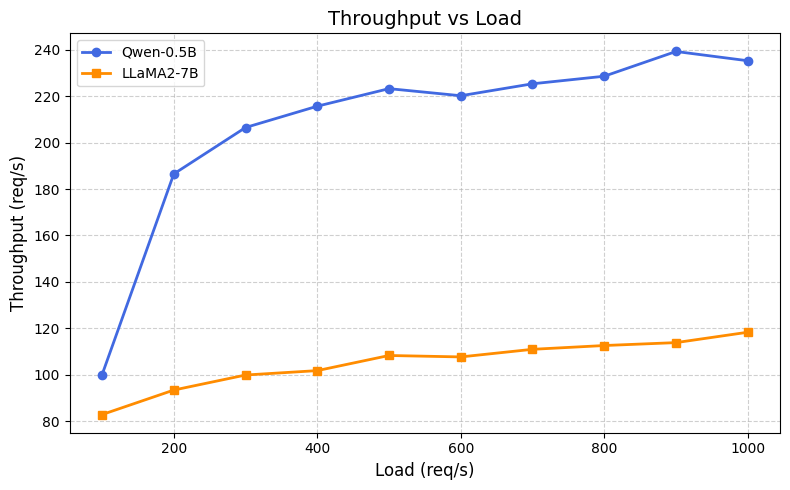

In [2]:
import matplotlib.pyplot as plt

# Intervals
intervals = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

# Throughput data
throughput_qwen = [99.98773534534443, 186.52291094333296, 206.5232479305066,
                   215.70670336651406, 223.2702270767458, 220.2173660010769, 
                   225.36470422642265, 228.6223673750933, 239.28226896522872, 235.29745905252258]

throughput_llama2 = [82.83540483694274 , 93.39553907186615, 99.87663272379658,
                     101.77422640966954, 108.29003295144597, 107.6749842927708,
                     110.95188862297704, 112.58498552960664, 113.83836812019733,
                     118.30899628896034]

# Plot
plt.figure(figsize=(8, 5))
plt.plot(intervals, throughput_qwen, marker='o', color='royalblue', linewidth=2, label='Qwen-0.5B')
plt.plot(intervals, throughput_llama2, marker='s', color='darkorange', linewidth=2, label='LLaMA2-7B')

# Labels and title
plt.title("Throughput vs Load", fontsize=14)
plt.xlabel("Load (req/s)", fontsize=12)
plt.ylabel("Throughput (req/s)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()

plt.savefig("../../results/throughput_vs_load_vllm_prefix_caching.png")


['ID']
['GPU', '0', '0.000', '0.000']
['GPU', '0', '0.039', '0.005']
['GPU', '0', '0.038', '0.005']
['GPU', '0', '0.039', '0.005']
['GPU', '0', '0.064', '0.029']
['GPU', '0', '0.007', '0.001']
['GPU', '0', '0.040', '0.005']
['GPU', '0', '0.038', '0.005']
['GPU', '0', '0.093', '0.032']
['GPU', '0', '0.000', '0.000']
['GPU', '0', '0.040', '0.005']
['GPU', '0', '0.042', '0.005']
['GPU', '0', '0.084', '0.031']
['GPU', '0', '0.000', '0.000']
['GPU', '0', '0.028', '0.004']
['ID']
['GPU', '0', '0.038', '0.005']
['GPU', '0', '0.039', '0.005']
['GPU', '0', '0.073', '0.030']
['GPU', '0', '0.001', '0.000']
['GPU', '0', '0.041', '0.005']
['GPU', '0', '0.035', '0.004']
['GPU', '0', '0.038', '0.005']
['GPU', '0', '0.062', '0.027']
['GPU', '0', '0.024', '0.003']
['GPU', '0', '0.038', '0.005']
['GPU', '0', '0.079', '0.030']
['GPU', '0', '0.001', '0.000']
['GPU', '0', '0.041', '0.005']
['GPU', '0', '0.035', '0.004']
['ID']
['GPU', '0', '0.037', '0.005']
['GPU', '0', '0.062', '0.027']
['GPU', '0', '0.00

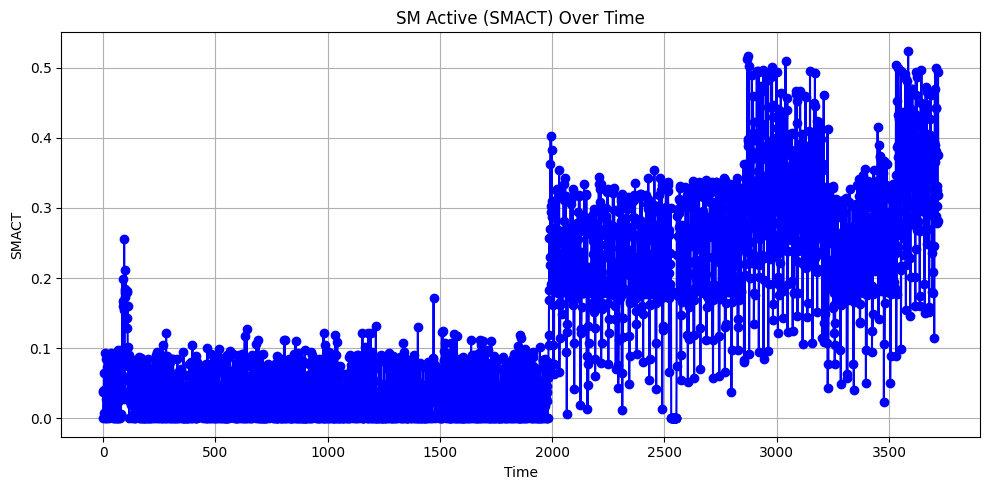

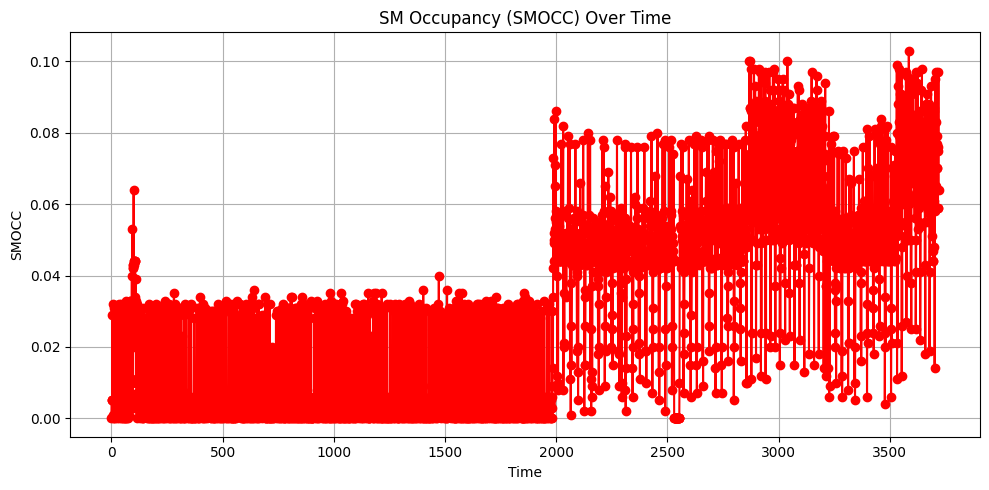

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Step 1: Read and clean the file ---
file_path = ".out_100"   # change this to your actual file name

# Read only the lines with data (skip header and footer lines starting with '#')
data = []
with open(file_path, "r") as f:
    for line in f:
        if line.strip() and not line.startswith("#"):
            parts = line.split()
            if len(parts) == 4:
                _, _, smact, smocc = parts
                data.append((float(smact), float(smocc)))

# Create a DataFrame
df = pd.DataFrame(data, columns=["SMACT", "SMOCC"])
# --- Step 2: Plot SMACT ---
plt.figure(figsize=(10, 5))
plt.plot(df["SMACT"], marker='o', linestyle='-', color='b')
plt.title("SM Active (SMACT) Over Time")
plt.xlabel("Time")
plt.ylabel("SMACT")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Step 3: Plot SMOCC ---
plt.figure(figsize=(10, 5))
plt.plot(df["SMOCC"], marker='o', linestyle='-', color='r')
plt.title("SM Occupancy (SMOCC) Over Time")
plt.xlabel("Time")
plt.ylabel("SMOCC")
plt.grid(True)
plt.tight_layout()
plt.show()


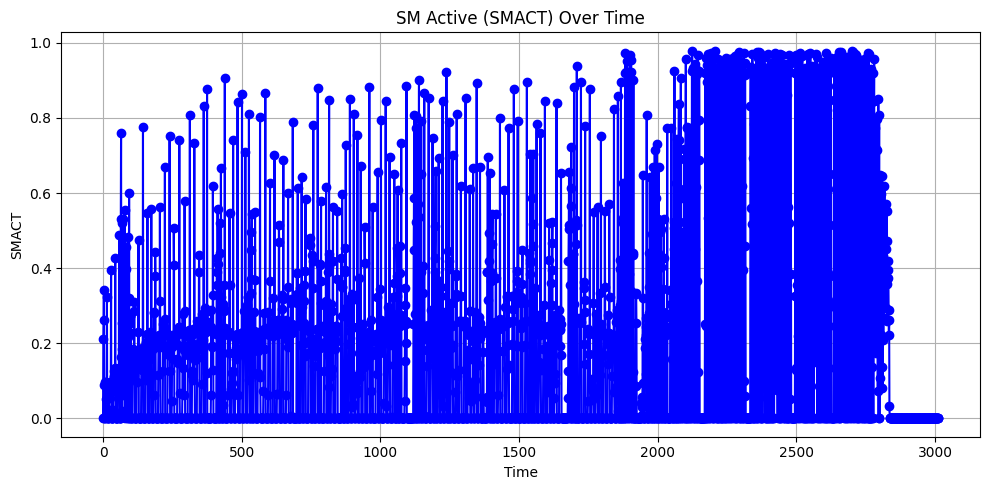

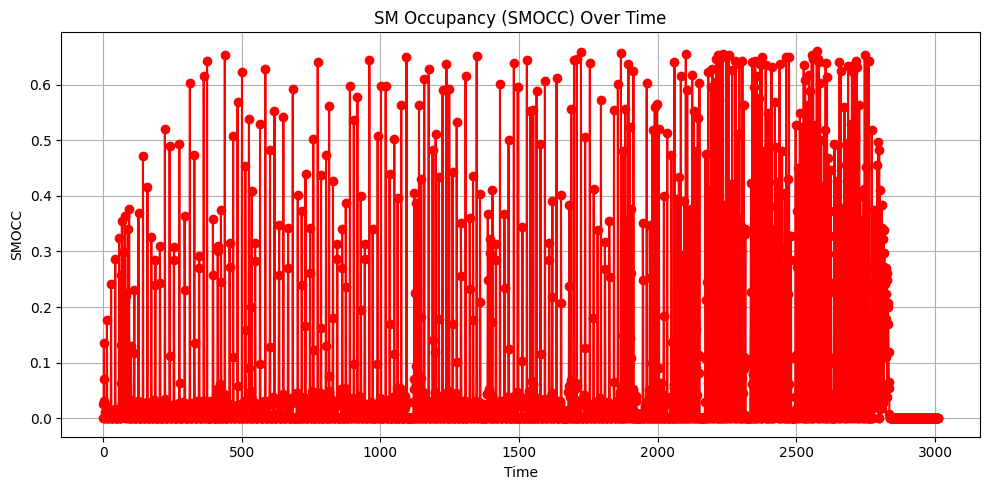

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Step 1: Read and clean the file ---
file_path = ".out_1000"   # change this to your actual file name

# Read only the lines with data (skip header and footer lines starting with '#')
data = []
with open(file_path, "r") as f:
    for line in f:
        if line.strip() and not line.startswith("#"):
            parts = line.split()
            if len(parts) == 4:
                _, _, smact, smocc = parts
                data.append((float(smact), float(smocc)))

# Create a DataFrame
df = pd.DataFrame(data, columns=["SMACT", "SMOCC"])
# --- Step 2: Plot SMACT ---
plt.figure(figsize=(10, 5))
plt.plot(df["SMACT"], marker='o', linestyle='-', color='b')
plt.title("SM Active (SMACT) Over Time")
plt.xlabel("Time")
plt.ylabel("SMACT")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Step 3: Plot SMOCC ---
plt.figure(figsize=(10, 5))
plt.plot(df["SMOCC"], marker='o', linestyle='-', color='r')
plt.title("SM Occupancy (SMOCC) Over Time")
plt.xlabel("Time")
plt.ylabel("SMOCC")
plt.grid(True)
plt.tight_layout()
plt.show()


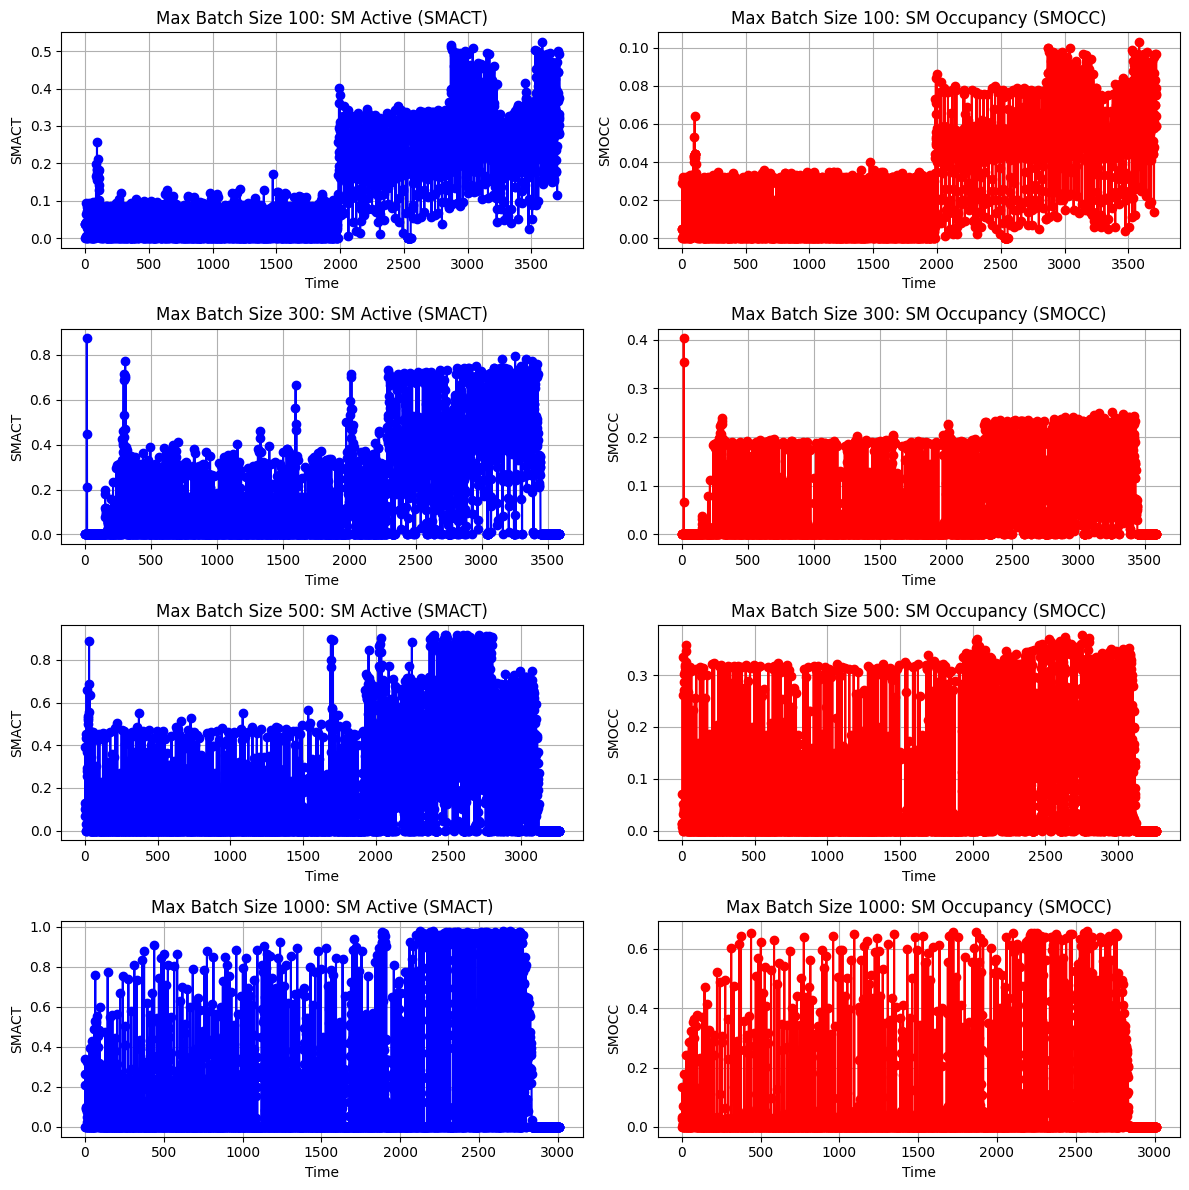

<Figure size 640x480 with 0 Axes>

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import re

# List of input files
files = [".out_100", ".out_300", ".out_500", ".out_1000"]

# Prepare a 4x2 grid for 8 plots
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 12))
fig.subplots_adjust(hspace=0.4, wspace=0.3)

for i, file_path in enumerate(files):
    # Extract batch size (last number in the filename)
    match = re.search(r"(\d+)", file_path)
    batch_size = match.group(1) if match else "?"

    # --- Read data ---
    data = []
    with open(file_path, "r") as f:
        for line in f:
            if line.strip() and not line.startswith("#"):
                parts = line.split()
                if len(parts) == 4:
                    _, _, smact, smocc = parts
                    data.append((float(smact), float(smocc)))

    df = pd.DataFrame(data, columns=["SMACT", "SMOCC"])

    # --- Plot SMACT ---
    ax1 = axes[i, 0]
    ax1.plot(df["SMACT"], marker='o', linestyle='-', color='b')
    ax1.set_title(f"Max Batch Size {batch_size}: SM Active (SMACT)")
    ax1.set_xlabel("Time")
    ax1.set_ylabel("SMACT")
    ax1.grid(True)

    # --- Plot SMOCC ---
    ax2 = axes[i, 1]
    ax2.plot(df["SMOCC"], marker='o', linestyle='-', color='r')
    ax2.set_title(f"Max Batch Size {batch_size}: SM Occupancy (SMOCC)")
    ax2.set_xlabel("Time")
    ax2.set_ylabel("SMOCC")
    ax2.grid(True)

plt.tight_layout()
plt.show()
plt.savefig("../../results/smact_smocc_batch_sizes.png")